# Part 1 — Kiểm tra trùng lặp, kiểm tra null, kiểm tra tương quan.
Chỉ kiểm tra `Dữ liệu sau tiền xử lí train.csv`.

In [1]:
# 1) Setup & Load Data
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Đọc dữ liệu train 
dataset = pd.read_csv('Dữ liệu sau tiền xử lí train.csv')


print("--- THÔNG TIN DỮ LIỆU ---")
print(dataset.info())
print("\n--- THỐNG KÊ MÔ TẢ ---")
print(dataset.describe())

--- THÔNG TIN DỮ LIỆU ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7778 entries, 0 to 7777
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   age                             7778 non-null   float64
 1   hypertension                    7778 non-null   int64  
 2   heart_disease                   7778 non-null   int64  
 3   avg_glucose_level               7778 non-null   float64
 4   bmi                             7778 non-null   float64
 5   gender_Male                     7778 non-null   bool   
 6   gender_Other                    7778 non-null   bool   
 7   ever_married_Yes                7778 non-null   bool   
 8   work_type_Never_worked          7778 non-null   bool   
 9   work_type_Private               7778 non-null   bool   
 10  work_type_Self-employed         7778 non-null   bool   
 11  work_type_children              7778 non-null   bool   
 12  Residenc

In [72]:
# 2) Duplicate & Null Check
print("\n--- KIỂM TRA TRÙNG LẶP ---")
print(f"Số dòng trùng lặp: {dataset.duplicated().sum()}") #  Kiểm tra số lượng các hàng bị trùng lặp hoàn toàn trong DataFrame dataset.


print("\n--- KIỂM TRA GIÁ TRỊ THIẾU ---")
print(dataset.isnull().sum()) # Số lượng giá trị thiếu (NaN hoặc null) cho từng cột.


--- KIỂM TRA TRÙNG LẶP ---
Số dòng trùng lặp: 0

--- KIỂM TRA GIÁ TRỊ THIẾU ---
age                               0
hypertension                      0
heart_disease                     0
avg_glucose_level                 0
bmi                               0
gender_Male                       0
gender_Other                      0
ever_married_Yes                  0
work_type_Never_worked            0
work_type_Private                 0
work_type_Self-employed           0
work_type_children                0
Residence_type_Urban              0
smoking_status_formerly smoked    0
smoking_status_never smoked       0
smoking_status_smokes             0
stroke                            0
dtype: int64


In [73]:
# 3) Correlation Check
target_col = 'stroke' if 'stroke' in dataset.columns else dataset.columns[-1] # Kiểm tra xem cột 'stroke' có tồn tại không, nếu không thì lấy cột cuối cùng.


print(f"\n--- TƯƠNG QUAN (|corr| với {target_col}, giảm dần) ---") # Xem những biến nào có mức độ liên hệ mạnh nhất (bất kể là tương quan dương hay âm).
print(dataset.corr()[target_col].abs().sort_values(ascending=False))


print(f"\n--- TƯƠNG QUAN (corr gốc, giảm dần) ---") # Xem các biến liên hệ tích cực (dương) mạnh mẽ nhất và sau đó các biến liên hệ tiêu cực (âm) yếu nhất.
print(dataset.corr()[target_col].sort_values(ascending=False))


--- TƯƠNG QUAN (|corr| với stroke, giảm dần) ---
stroke                            1.000000
age                               0.596758
ever_married_Yes                  0.379375
work_type_children                0.263729
avg_glucose_level                 0.227255
smoking_status_formerly smoked    0.187273
work_type_Self-employed           0.184753
Residence_type_Urban              0.147296
gender_Male                       0.110796
bmi                               0.106367
work_type_Private                 0.101955
hypertension                      0.095279
heart_disease                     0.091552
smoking_status_smokes             0.064371
work_type_Never_worked            0.040917
smoking_status_never smoked       0.023584
gender_Other                      0.011340
Name: stroke, dtype: float64

--- TƯƠNG QUAN (corr gốc, giảm dần) ---
stroke                            1.000000
age                               0.596758
ever_married_Yes                  0.379375
avg_glucose_level   

- Dataset đạt yêu cầu → dùng train model.

- Loại 2 biến rất yếu:

        smoking_status_never smoked (0.023584)

        gender_Other (0.011340)

- ->Loại trên cả train và test.

# HUẤN LUYỆN MÔ HÌNH QUY CƠ VỀ BỆNH ĐỘT QUỴ

## I. Các thư viện hổ trợ cho Model

In [74]:
# --- KHAI BÁO CÁC THƯ VIỆN CẦN DÙNG ĐỂ HUẤN LUYỆN VÀ ĐÁNH GIÁ MÔ HÌNH ---

import pandas as pd                                 # Xử lý dữ liệu dạng bảng (CSV, Excel, SQL...), hỗ trợ DataFrame tiện cho phân tích
import seaborn as sns                               # Thư viện vẽ biểu đồ
import matplotlib.pyplot as plt                     # Thư viện vẽ biểu đồ xây dựng trên matplotlib
import xgboost as xgb                             # Thư viện XGBoost để xây dựng mô hình tăng cường
from sklearn.model_selection import train_test_split            # chia dữ liệu train/test
from sklearn.pipeline import Pipeline                           # nối các bước xử lý dữ liệu và huấn luyện mô hình thành một thể thống nhất.
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression             # để tạo mô hình Logistic Regression
from sklearn.tree import DecisionTreeClassifier                 # để tạo mô hình Decision Tree
from sklearn.svm import SVC                                     # để tạo mô hình Support Vector Classifier
from sklearn.ensemble import RandomForestClassifier             # để tạo mô hình Random Forest
# ...
from sklearn.metrics import (
    accuracy_score,                                    # Tính độ tin cậy về tỉ lệ dự đoán đúng của model
    classification_report,                             # Báo cáo các chỉ số precision, recall, f1-score
    confusion_matrix,                                  # Ma trận nhầm lẫn để có các giá trị TP, TN, FP, FN
    roc_auc_score,                                     # Tính các chỉ số ROC, AUC để đánh giá khả năng phân biệt tổng thể Model
    ConfusionMatrixDisplay,                             # Vẽ trực quan ma trận nhầm lẫn
)

## II. Đọc dữ liệu

In [75]:
df_train = pd.read_csv("Dữ liệu sau tiền xử lí train.csv")
df_train.drop(columns='gender_Other', inplace=True)
df_train.drop(columns='smoking_status_never smoked', inplace=True)
print("In 5 dòng đầu của dữ liệu train")
df_train.head()

In 5 dòng đầu của dữ liệu train


,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Male,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_smokes,stroke
0,0.205661,0,0,-0.960346,0.616266,False,True,False,True,False,False,True,False,False,0
1,-1.254901,0,0,0.632522,-1.079182,True,False,False,True,False,False,False,False,False,0
2,1.046590,0,0,0.277250,-0.532715,False,True,False,False,True,False,False,False,False,0
3,0.028623,0,0,-1.074466,-0.546727,True,True,False,True,False,False,True,False,True,0
4,-1.299160,0,0,-0.566033,0.406086,True,False,False,False,False,False,True,False,False,0


In [76]:
df_test = pd.read_csv("Dữ liệu sau tiền xử lí test.csv")
print("In 5 dòng đầu của dữ liệu test")
df_test.drop(columns='gender_Other', inplace=True)
df_test.drop(columns='smoking_status_never smoked', inplace=True)
df_test.head()

In 5 dòng đầu của dữ liệu test


,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Male,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_smokes,stroke
0,0.869552,0,0,-0.689463,0.854469,True,True,False,True,False,False,False,False,False,0
1,-0.015636,0,0,-0.435997,0.644290,False,True,False,True,False,False,True,False,False,0
2,-0.900825,0,0,0.765261,-0.000260,False,False,False,True,False,False,True,False,True,0
3,-0.989344,0,0,2.052258,-0.532715,False,False,False,True,False,False,True,False,False,0
4,1.046590,0,0,0.364942,-0.336548,True,True,False,True,False,False,False,True,False,0


## III. Tách các feature(X) và label(Y)

In [77]:
X_train = df_train.drop(columns=['stroke'])
y_train = df_train['stroke']

X_test = df_test.drop(columns=['stroke'])
y_test = df_test['stroke']

### _ Mục đích của việc tách các cặp train và test nhằm để xác định các đầu vào của X và đầu ra của Y.

-Đầu vào X: được dùng cho mô hình sử đụng tìm ra các mẫu và các mối quan hệ và sẽ loại bỏ đi cột kết quả. - VD: Dữ liệu X (tuổi, huyết áp, mức glucose) như này có nguy cơ bị đột quỵ hay không?

-Đầu ra Y: sẽ là đưa ra kết quả khi mô hình dựa trên các đầu vào của X. - VD: Dự đoán kết quả của X này thì Y sẽ (Có/Không).

### _ Tại sao lại phân thành các cặp X_train, Y_train, X_test, Y_test

-Huấn luyện (Train): sẽ chiếm phần lớn dữ liệu (70%-90%) dùng cho việc cung cấp để dạy mô hình học khi có các đặc điểm của X_train thì sẽ có được kết quả Y_train cùng lúc. - VD: Khi có features "tuổi cao, hút thuốc, glucose cao" thì xác suất có kết quả stroke là rất cao.

-Kiểm thử (Test): chiếm phần nhỏ còn lại (10%-30%) được giữ kín lại dùng để đảm bảo và đánh giá mô hình có hiệu quả hay không. Nhằm tránh overfiting cho mô hình khi mà dạy hết cho mô hình 100% dữ liệu. Vì nếu mô hình chỉ hoạt động tốt trên tập kiểm thử nhưng khi gặp dữ liệu mới hoàn toàn thì mô hình lại đánh giá sai. Nên cần cặp test để tránh mô hình học vẹt, học chi tiết nhỏ nhặt và nhiễu (noise) của dữ liệu huấn luyện, khiến nó kém linh hoạt khi gặp dữ liệu mới.

## IV.Huấn luyện mô hình

### 1.Mô hình logistic regression

In [78]:
# Pipeline xâu chuỗi các bước xử lý + mô hình trong cùng 1 đối tượng để tránh rò rỉ dữu liệu do sẽ chỉ fit trên dữu liệu train và đảm bảo test.
log_reg_pipe = Pipeline([
    ('scaler', StandardScaler()),                           # Bước chuẩn hóa các feature về mean = 0, std = 1
    ('logreg', LogisticRegression(random_state = 42, class_weight = "balanced"))         # Huấn luyện mô hình Logistic regression.
])

random_sate = 42 để đảm bảo kết quả có thể tái lập

class_weight = "balanced" mục đích tránh mất cân bằng cho dữ liệu

In [79]:
log_reg_pipe.fit(X_train, y_train)                              # Huấn luyện mô hình
print("✅ Đã huấn luyện Logistic Regression thành công.")

✅ Đã huấn luyện Logistic Regression thành công.


Tự động thực hiện tất cả các bước theo thứ tự, từ preprocessing → model training, đảm bảo train/test tách biệt, tránh lỗi rò rỉ dữ liệu.

### 2.Mô hình decision tree

In [80]:
# Pipeline xâu chuỗi các bước xử lý + mô hình trong cùng 1 đối tượng để tránh rò rỉ dữu liệu do sẽ chỉ fit trên dữu liệu train và đảm bảo test.
tree_pipe = Pipeline([
    ('tree', DecisionTreeClassifier(random_state = 42, max_depth = 5, class_weight = "balanced"))
])

max_depth=5 để tạo cây quyết định với độ sâu tối đa = 5 giúp tránh được tình trạng overfiting.

random_state=42  đảm bảo kết quả tái lập.

Do mô hình decision tree được chia theo ngưỡng không bị ảnh hưởng bởi đơn vị đo nên không cần chuẩn hóa scaler


In [81]:
tree_pipe.fit(X_train, y_train)                                 # Huấn luyện mô hình
print("✅ Đã huấn luyện Decision Tree thành công.")

✅ Đã huấn luyện Decision Tree thành công.


Tự động thực hiện tất cả các bước theo thứ tự, từ preprocessing → model training, đảm bảo train/test tách biệt, tránh lỗi rò rỉ dữ liệu.

### 3.Mô hình SVM

In [82]:
svm_pipe = Pipeline([
    ('scaler', StandardScaler()),                                       # Bước chuẩn hóa các feature về mean = 0, std = 1
    ('svm', SVC(kernel='rbf', probability=True, random_state=42, class_weight = "balanced"))
])

RBF kernel (phi tuyến tính), giúp mô hình phân tách dữ liệu không linearly separable.

Mặc định của SVM chỉ trả nhãn predict(). Nên cần có probability=True để SVM dùng Platt scaling ước lượng xác suất.

In [83]:
svm_pipe.fit(X_train, y_train)
print("✅ Đã huấn luyện SVM thành công.")


✅ Đã huấn luyện SVM thành công.


### 4.Mô hình Random Forest


In [84]:
rf_pipe = Pipeline([
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42, class_weight = "balanced"))
])

Do mô hình random forest cũng được chia theo ngưỡng không bị ảnh hưởng bởi đơn vị đo nên không cần chuẩn hóa scaler

n_estimators=100: số lượng cây quyết định (Decision Trees) trong rừng dùng để dự đoán ổn định, chính xác hơn

In [85]:
rf_pipe.fit(X_train, y_train)
print("✅ Đã huấn luyện Random Forest thành công.")

✅ Đã huấn luyện Random Forest thành công.


### 5.Mô hình XGBoost

In [97]:
xgb_pipe = Pipeline([
    ('xgb', xgb.XGBClassifier( objective='binary:logistic', n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42))
])

objective='binary:logistic': Dành cho phân loại nhị phân

use_label_encoder=False: Tránh cảnh báo trong các phiên bản mới

eval_metric='logloss': Chỉ số đánh giá

In [98]:
xgb_pipe.fit(X_train, y_train)
print("✅ Đã huấn luyện XGBoost thành công.")

✅ Đã huấn luyện XGBoost thành công.


## V.Dự đoán mô hình

### 1.Dự đoán của mô hình logictis regression

In [88]:
y_pred_lr = log_reg_pipe.predict(X_test)                            # Sử dụng dữ liệu của X_test để dự đoán kết quả.
y_pred_proba_lr = log_reg_pipe.predict_proba(X_test)[:, 1]          # xác suất dự đoán cho lớp nguy cơ đột quỵ

_ Dùng hàm predict() để sử dụng dữ liệu của test dự đoán kết quả.

_ Dùng hàm predict_proba() để lấy xác suất dự đoán cho lớp nguy cơ đột quỵ dùng để đánh giá mô hình bằng các chỉ số như ROC-AUC, hoặc để tùy chỉnh ngưỡng quyết định cho nhãn.

### 2.Dự đoán của mô hình decision tree

In [89]:
y_pred_tree = tree_pipe.predict(X_test)                             # Sử dụng dữ liệu của X_test để dự đoán kết quả.
y_pred_proba_tree = tree_pipe.predict_proba(X_test)[:, 1]           # xác suất dự đoán cho lớp nguy cơ đột quỵ

### 3.Dự đoán của mô hình SVM

In [90]:
y_pred_svm = svm_pipe.predict(X_test)                           # Sử dụng dữ liệu của X_test để dự đoán kết quả.
y_pred_proba_svm = svm_pipe.predict_proba(X_test)[:, 1]         # xác suất dự đoán cho lớp nguy cơ đột quỵ

### 4.Dự đoán của mô hình Random Forest

In [91]:
y_pred_rf = rf_pipe.predict(X_test)                           # Sử dụng dữ liệu của X_test để dự đoán kết quả.
y_pred_proba_rf = rf_pipe.predict_proba(X_test)[:, 1]         # xác suất dự đoán cho lớp nguy cơ đột quỵ

### 5.Dự đoán của mô hình XGBoost

In [99]:
y_pred_xgb = xgb_pipe.predict(X_test)                              # Sử dụng dữ liệu của X_test để dự đoán kết quả.
y_pred_proba_xgb = xgb_pipe.predict_proba(X_test)[:, 1]            # xác suất dự đoán cho lớp nguy cơ đột quỵ

## VI.Đánh giá hiệu năng của mô hình

### 1.Hiệu năng của mô hình logistic regression

+-+-+ Logistic Regression Classifier +-+-+

Accuracy: 0.7671232876712328
----------------------------------------------------------------------------------------------------
Confusion Matrix:


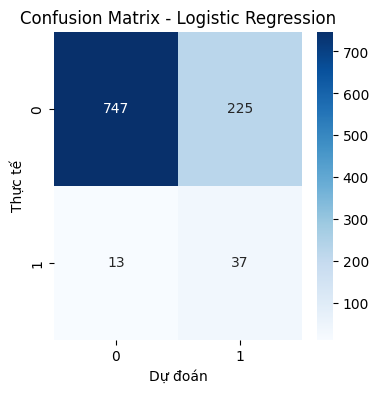

----------------------------------------------------------------------------------------------------
Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.77      0.86       972
           1       0.14      0.74      0.24        50

    accuracy                           0.77      1022
   macro avg       0.56      0.75      0.55      1022
weighted avg       0.94      0.77      0.83      1022

----------------------------------------------------------------------------------------------------
ROC - AUC: 0.8326337448559671


In [93]:
print("+-+-+ Logistic Regression Classifier +-+-+")

accuracy = accuracy_score(y_test, y_pred_lr)                    # Đánh giá phần trăm dự đoán đúng của test
print("\nAccuracy:", accuracy)
print('-'*100)

print("Confusion Matrix:")                                      # Ma trận nhầm lẫn cho biết TN, FN, TP, FP
cm = confusion_matrix(y_test, y_pred_lr)
plt.figure(figsize=(4,4))
sns.heatmap(
    cm,
    annot = True,           # in giá trị trong mỗi ô
    fmt = "d",              # định dạng số nguyên
    cmap = "Blues"          # màu xanh
)
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.show()
print('-'*100)

report = classification_report(y_test, y_pred_lr)               # Đánh giá chi tiết các Pre, Recall, F1-score
print("Classification Report:\n", report)
print('-'*100)

roc_auc = roc_auc_score(y_test, y_pred_proba_lr)                # Khả năng phân biệt 2 lớp
print("ROC - AUC:", roc_auc)


### 2.Hiệu năng của mô hình decision tree

+-+-+ Decision Tree Classifier +-+-+

Accuracy: 0.7250489236790607
----------------------------------------------------------------------------------------------------
Confusion Matrix:


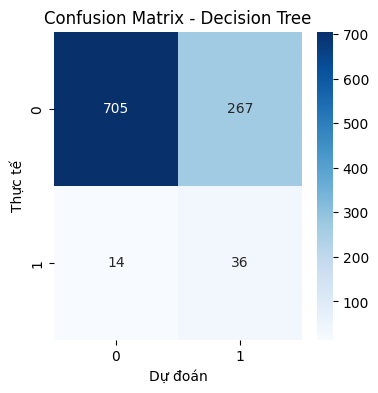

----------------------------------------------------------------------------------------------------
Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.73      0.83       972
           1       0.12      0.72      0.20        50

    accuracy                           0.73      1022
   macro avg       0.55      0.72      0.52      1022
weighted avg       0.94      0.73      0.80      1022

----------------------------------------------------------------------------------------------------
ROC - AUC: 0.783261316872428


In [94]:
print("+-+-+ Decision Tree Classifier +-+-+")

accuracy = accuracy_score(y_test, y_pred_tree)                    # Đánh giá phần trăm dự đoán đúng của test
print("\nAccuracy:", accuracy)
print('-'*100)

print("Confusion Matrix:")                                      # Ma trận nhầm lẫn cho biết TN, FN, TP, FP
cm = confusion_matrix(y_test, y_pred_tree)
plt.figure(figsize=(4,4))
sns.heatmap(
    cm,
    annot = True,           # in giá trị trong mỗi ô
    fmt = "d",              # định dạng số nguyên
    cmap = "Blues"          # màu xanh
)
plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.show()
print('-'*100)

report = classification_report(y_test, y_pred_tree)               # Đánh giá chi tiết các Pre, Recall, F1-score
print("Classification Report:\n", report)
print('-'*100)

roc_auc = roc_auc_score(y_test, y_pred_proba_tree)                # Khả năng phân biệt 2 lớp
print("ROC - AUC:", roc_auc)

### 3.Hiệu năng của mô hình SVM

+-+-+ Support Vector Classifier +-+-+

Accuracy: 0.7954990215264188
----------------------------------------------------------------------------------------------------
Confusion Matrix:


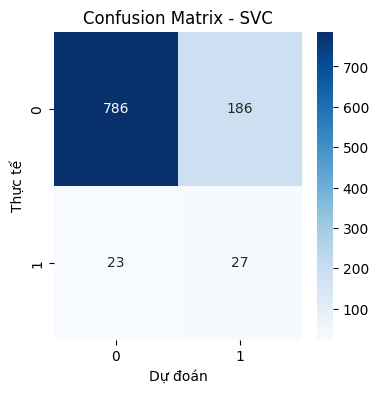

----------------------------------------------------------------------------------------------------
Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.81      0.88       972
           1       0.13      0.54      0.21        50

    accuracy                           0.80      1022
   macro avg       0.55      0.67      0.54      1022
weighted avg       0.93      0.80      0.85      1022

----------------------------------------------------------------------------------------------------
ROC - AUC: 0.7402263374485597


In [95]:
print("+-+-+ Support Vector Classifier +-+-+")

accuracy = accuracy_score(y_test, y_pred_svm)                    # Đánh giá phần trăm dự đoán đúng của test
print("\nAccuracy:", accuracy)
print('-'*100)

print("Confusion Matrix:")                                      # Ma trận nhầm lẫn cho biết TN, FN, TP, FP
cm = confusion_matrix(y_test, y_pred_svm)
plt.figure(figsize=(4,4))
sns.heatmap(
    cm,
    annot = True,           # in giá trị trong mỗi ô
    fmt = "d",              # định dạng số nguyên
    cmap = "Blues"          # màu xanh
)
plt.title("Confusion Matrix - SVC")
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.show()
print('-'*100)

report = classification_report(y_test, y_pred_svm)               # Đánh giá chi tiết các Pre, Recall, F1-score
print("Classification Report:\n", report)
print('-'*100)

roc_auc = roc_auc_score(y_test, y_pred_proba_svm)                # Khả năng phân biệt 2 lớp
print("ROC - AUC:", roc_auc)

### 4. Hiệu năng của mô hình Random Forest

+-+-+ Random Forest Classifier +-+-+

Accuracy: 0.8845401174168297
----------------------------------------------------------------------------------------------------
Confusion Matrix:


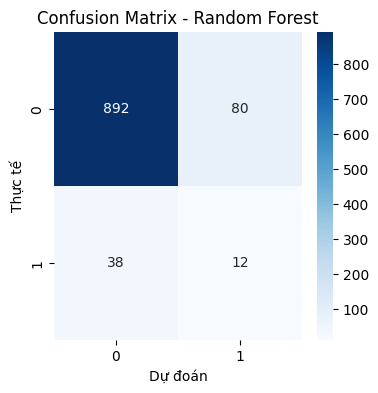

----------------------------------------------------------------------------------------------------
Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.92      0.94       972
           1       0.13      0.24      0.17        50

    accuracy                           0.88      1022
   macro avg       0.54      0.58      0.55      1022
weighted avg       0.92      0.88      0.90      1022

----------------------------------------------------------------------------------------------------
ROC - AUC: 0.7562037037037037


In [96]:
print("+-+-+ Random Forest Classifier +-+-+")

accuracy = accuracy_score(y_test, y_pred_rf)                    # Đánh giá phần trăm dự đoán đúng của test
print("\nAccuracy:", accuracy)
print('-'*100)

print("Confusion Matrix:")                                      # Ma trận nhầm lẫn cho biết TN, FN, TP, FP
cm = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(4,4))
sns.heatmap(
    cm,
    annot = True,           # in giá trị trong mỗi ô
    fmt = "d",              # định dạng số nguyên
    cmap = "Blues"          # màu xanh
)
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.show()
print('-'*100)

report = classification_report(y_test, y_pred_rf)               # Đánh giá chi tiết các Pre, Recall, F1-score
print("Classification Report:\n", report)
print('-'*100)

roc_auc = roc_auc_score(y_test, y_pred_proba_rf)                # Khả năng phân biệt 2 lớp
print("ROC - AUC:", roc_auc)

### 5. Hiệu năng của mô hình XGBoost

+-+-+ XGBoost Classifier +-+-+

Accuracy: 0.8483365949119374
----------------------------------------------------------------------------------------------------
Confusion Matrix:


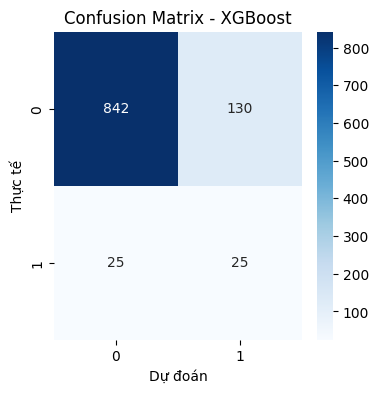

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.87      0.92       972
           1       0.16      0.50      0.24        50

    accuracy                           0.85      1022
   macro avg       0.57      0.68      0.58      1022
weighted avg       0.93      0.85      0.88      1022

----------------------------------------------------------------------------------------------------
ROC - AUC: 0.8018106995884774


In [100]:
print("+-+-+ XGBoost Classifier +-+-+")

accuracy = accuracy_score(y_test, y_pred_xgb)                    # Đánh giá phần trăm dự đoán đúng của test
print("\nAccuracy:", accuracy)
print('-'*100)

print("Confusion Matrix:")                                      # Ma trận nhầm lẫn cho biết TN, FN, TP, FP
cm = confusion_matrix(y_test, y_pred_xgb)
plt.figure(figsize=(4,4))
sns.heatmap(
    cm,
    annot = True,           # in giá trị trong mỗi ô
    fmt = "d",              # định dạng số nguyên
    cmap = "Blues"          # màu xanh
)
plt.title("Confusion Matrix - XGBoost")
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.show() # print('-'*100)

report = classification_report(y_test, y_pred_xgb)               # Đánh giá chi tiết các Pre, Recall, F1-score
print("Classification Report:\n", report)
print('-'*100)

roc_auc = roc_auc_score(y_test, y_pred_proba_xgb)                # Khả năng phân biệt 2 lớp
print("ROC - AUC:", roc_auc)

## VII.Tổng kết

### 1. So sánh Hiệu năng Mô hình Dự đoán Nguy cơ Đột quỵ

| Chỉ số | Logistic Regression (LR) | Decision Tree (DT) | Support Vector Machine (SVM) | Random Forest (RF) | XGBoost (XGB) |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Accuracy (Tổng quát)** | 0.77 | 0.73 | 0.80 | **0.88** | 0.85 |
| **Recall (Lớp 1)** | **0.740** | 0.72 | 0.54 | 0.24 | 0.50 |
| **Precision (Lớp 1)** | 0.14 | 0.12 | 0.13 | 0.13 | **0.16** |
| **F1-Score (Lớp 1)** | **0.24** | 0.20 | 0.21 | 0.17 | **0.24** |
| **ROC - AUC** | **0.833** | 0.783 | 0.74 | 0.756 | 0.80 |

## 2. Đánh giá Khả năng Vượt trội và Hạn chế của Các Mô hình

| **Mô hình** | **Điểm mạnh (Ưu tiên theo mục tiêu phát hiện nguy cơ – Recall)** | **Hạn chế** |
|-------------|------------------------------------------------------------------|-------------|
| **Logistic Regression (LR)** | - **Recall lớp 1 cao nhất (0.740)** → phát hiện được nhiều ca nguy cơ nhất. <br> - **ROC-AUC cao nhất (0.833)** → khả năng phân biệt tốt hai lớp. | - **Precision thấp (0.140)** → nhiều cảnh báo sai. <br> - **F1-Score thấp (0.240)** → mất cân bằng Precision–Recall. |
| **Decision Tree (DT)** | - **Recall lớp 1 tốt (0.720)** → đứng thứ hai về khả năng phát hiện ca nguy cơ. | - Precision thấp (0.120). <br> - F1-Score thấp (0.200). <br> - ROC-AUC chỉ 0.783. <br> - Mô hình dễ bị Overfitting. |
| **Support Vector Machine (SVM)** | - **Accuracy tổng thể tốt (0.800)** → mô hình ổn định. | - **Recall thấp (0.540)** → bỏ sót 46% ca nguy cơ. <br> - Precision thấp (0.130). |
| **Random Forest (RF)** | - **Accuracy cao nhất (0.880)** → mô hình dự đoán tổng thể mạnh nhất. | - **Recall cực thấp (0.240)** → hầu như không phát hiện được ca nguy cơ. <br> - ROC-AUC thấp nhất (0.756). <br> - Không phù hợp mục tiêu phát hiện sớm đột quỵ. |
| **XGBoost (XGB)** | - **Precision lớp 1 cao nhất trong nhóm cây (0.160)**. <br> - F1-Score tốt hơn RF/DT. | - Recall thấp (0.500). <br> - Hiệu năng tổng thể chưa vượt LR. |


---

## 3. Kết luận và Định hướng Phát triển

### **3.1 Kết luận tổng quan**

- Không có mô hình nào mạnh nhất ở tất cả tiêu chí.  
- Nếu **ưu tiên phát hiện đúng người có nguy cơ đột quỵ (Recall cao)** → dùng Logistic Regression (LR).  
- Nếu ưu tiên **độ chính xác tổng thể (Accuracy)** → dùng Random Forest (RF).  

---

### **3.2 Mô hình phù hợp nhất**

## **Hồi quy Logistic (LR) là mô hình cân bằng tốt nhất**

**Lý do chọn LR:**
- **Recall lớp 1 cao nhất: 0.740** → phát hiện được phần lớn ca nguy cơ.  
- **ROC-AUC cao nhất: 0.833** → phân biệt hai lớp dữ liệu tốt nhất.  
- Dù Precision thấp, nhưng với bài toán **cảnh báo bệnh**, Recall quan trọng hơn Precision.

👉 **Kết luận:** LR là mô hình phù hợp nhất để dự đoán sớm nguy cơ đột quỵ.


---

### **3.3 Mô hình không phù hợp**

- **Random Forest (RF)**: mặc dù Accuracy cao (0.880), nhưng **Recall chỉ 0.240** → bỏ sót 76% ca nguy cơ.  
→ Không phù hợp cho mục tiêu cảnh báo bệnh.


---

### **3.4 Định hướng Phát triển và Cải thiện Mô hình**

#### **1. Giải quyết mất cân bằng dữ liệu (Data Imbalance)**  
- Sử dụng **SMOTE hoặc ADASYN** để tăng số mẫu lớp 1 (đột quỵ).  
- Giúp tăng Precision và F1-Score cho LR.

#### **2. Thử thêm các mô hình Boosting / Ensemble**
- Tối ưu LightGBM, XGBoost.  
- Thường cho F1 và ROC-AUC cao hơn mô hình cơ bản.

#### **3. Tối ưu siêu tham số (Hyperparameter Tuning)**
- Dùng GridSearchCV hoặc RandomizedSearchCV.

#### **4. Điều chỉnh Threshold**
- Giảm ngưỡng phân loại từ 0.5 xuống (0.3 – 0.4).  
- Tăng Recall cho LR.

---